# SCIN model data setup

Imports and cleaned-data loading only. Run the export cell in `SCIN_EDA.ipynb` first.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd


In [2]:
notebook_dir = Path.cwd()
if not (notebook_dir / "SCIN_MODEL.IPYNB").is_file():
    notebook_dir = notebook_dir / "notebooks"
if not (notebook_dir / "SCIN_MODEL.IPYNB").is_file():
    raise FileNotFoundError("Run from the notebooks folder or repository root.")

data_path = notebook_dir / "SCIN_cleaned.pkl"
# Only load this locally generated pickle; pickle files from others can execute code.
cleaned_data = pd.read_pickle(data_path)

df = cleaned_data["df"]
X_metadata = cleaned_data["X_metadata"]
X_images = cleaned_data["X_images"]
y = cleaned_data["y"]
Y = cleaned_data["Y"]
target_classes = cleaned_data["target_classes"]
image_cols = cleaned_data["image_cols"]
binary_features = cleaned_data["binary_features"]
categorical_features = cleaned_data["categorical_features"]


## Multimodal pipeline (existing cleaned artifacts only)

No EDA, cleaning or label selection is repeated. `Y` stays a dermatologist-weighted distribution across the existing 41 outputs. Only `image_1_path` is used; no multi-image fusion. Install the optional dependencies from the repository root with `.venv/bin/python -m pip install -r requirements-ml.txt`.


In [3]:
import json
import sys
from dataclasses import asdict
from datetime import datetime, timezone

import torch

repo_root = notebook_dir.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
# Keep the official transfer-learning download in a local, Git-ignored cache.
torch.hub.set_dir(str(repo_root / ".cache" / "torch" / "hub"))

from scin_ml.pipeline import prepare_data, select_device
from scin_ml.model import MultimodalDermatologyModel
from scin_ml.training import TrainingConfig, evaluate, fit, seed_everything
from scin_ml.inference import SCINPredictor, export_for_app


### Reproducible experiment settings

Run outputs go into a new directory so older exports remain intact. The default is five frozen-backbone epochs followed by up to fifteen fine-tuning epochs; each phase uses validation-loss early stopping with patience five. Phase two unfreezes the last three CNN feature blocks. The test set is not used for checkpoint selection.

One existing labeled case has no primary image (case `-1834609919572055750`). The explicit policy below records its exclusion from image-based training/evaluation without modifying the artifact or substituting a secondary image. Set the flag to `False` to stop instead. All 3,061 cases remain in the split manifest; usable counts are 2,142 / 458 / 460 with seed 42.


In [4]:
config = TrainingConfig(phase1_epochs=5, phase2_epochs=15, seed=42, image_size=224)
batch_size = 32
num_workers = 0  # Portable notebook default; avoids spawning notebook workers.
exclude_missing_primary = True
image_root = None  # Optional folder containing original image_1 filenames.
arrow_cache = None  # Defaults to the existing local Hugging Face SCIN cache.
run_dir = notebook_dir / "scin_runs" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
device = select_device("auto")
seed_everything(config.seed)
print("Device:", device)
print("Output directory:", run_dir)


Device: mps
Output directory: /Users/omarjibreen/College/Fall 2026/ProGSU/Hacklanta/PaliDerm/notebooks/scin_runs/20261011T081010519039Z


### Case-grouped split and training-only encoding

The same positional indices select image, metadata and label rows. Group checks reject leakage. Binary columns stay encoded; the five categorical vocabularies are learned only from usable training rows. Unseen validation/test/inference categories map to an all-zero category block. The saved JSON encoder preserves feature order.

Original cached images are matched by case ID and original filename, decoded to RGB, resized without stretching, centered on a 224×224 pad, and ImageNet-normalized. Numbered legacy image exports are not assumed to match labels.


In [5]:
prepared = prepare_data(
    data_path, run_dir, seed=config.seed, batch_size=batch_size,
    image_size=config.image_size, num_workers=num_workers,
    image_root=image_root, arrow_cache=arrow_cache,
    exclude_missing_primary=exclude_missing_primary,
)
assert prepared.artifacts.num_classes == len(target_classes) == 41
assert np.array_equal(prepared.artifacts.labels, Y)
assert prepared.artifacts.classes == tuple(target_classes)
train_loader = prepared.loaders["train"]
validation_loader = prepared.loaders["val"]
test_loader = prepared.loaders["test"]
print(json.dumps(prepared.report, indent=2))


{
  "artifact_sha256": "12c8c121a7669d3656337a5d5f3f0bb3dc64c08a036c9ff4d471795882bfb6d8",
  "total_labeled_rows": 3061,
  "num_classes": 41,
  "seed": 42,
  "primary_image_column": "image_1_path",
  "split_rows": {
    "train": 2142,
    "val": 459,
    "test": 460
  },
  "usable_split_rows": {
    "train": 2142,
    "val": 458,
    "test": 460
  },
  "excluded_missing_primary": [
    {
      "position": 163,
      "source_index": "270",
      "case_id": "-1834609919572055750",
      "reason": "Missing image_1_path; no image_2/image_3 substitution."
    }
  ],
  "exclusion_explicitly_enabled": true,
  "metadata_dim": 68,
  "batch_size": 32,
  "num_workers": 0,
  "image_size": 224,
  "image_source": "verified original filenames/local SCIN Arrow cache"
}


### Late-fusion architecture and soft-label training

MobileNetV3-Small → global average pool → 576→128 image projection. Metadata → 64→32. Concatenate 160 features → 128→41 logits. No softmax during training; cross entropy consumes the full soft `Y` distribution.

Phase 1 AdamW rates: fusion head 1e-3; new branches 1e-4. Phase 2: final CNN blocks 1e-5; new layers 1e-4. Weight decay 1e-4; ReduceLROnPlateau factor 0.5, patience 2. Frozen blocks also keep frozen BatchNorm statistics. The global best validation-loss checkpoint is restored.


In [6]:
seed_everything(config.seed)
model = MultimodalDermatologyModel(
    metadata_dim=prepared.encoder.output_dim,
    num_classes=len(target_classes),
    pretrained=True,
)
model


MultimodalDermatologyModel(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): SqueezeExcitation(
          (avgpool): AdaptiveAvgPool2d(output_size=1)
          (fc1): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1))
          (fc2): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1))
          (activation): ReLU()
          (scale_activation): Hardsigmoid()
        )
        (2): Conv2dNormActivation(
          (0)

In [7]:
training_result = fit(
    model, train_loader, validation_loader, run_dir, target_classes,
    config=config, device=device,
    metadata_encoder_path=run_dir / "metadata_encoder.json",
)
print("Best validation loss:", training_result.best_validation_loss)
print("Best epoch:", training_result.best_epoch)
print("Best checkpoint:", training_result.checkpoint_path)


Phase 1, epoch 1/5: train_loss=3.19908 val_loss=2.96593 top1=0.188 top3=0.528
Phase 1, epoch 2/5: train_loss=2.98555 val_loss=2.94895 top1=0.188 top3=0.528
Phase 1, epoch 3/5: train_loss=2.96228 val_loss=2.94201 top1=0.249 top3=0.528
Phase 1, epoch 4/5: train_loss=2.93203 val_loss=2.93401 top1=0.242 top3=0.528
Phase 1, epoch 5/5: train_loss=2.90860 val_loss=2.90730 top1=0.231 top3=0.524
Phase 2, epoch 1/15: train_loss=2.91625 val_loss=2.90945 top1=0.253 top3=0.522
Phase 2, epoch 2/15: train_loss=2.88742 val_loss=2.90654 top1=0.249 top3=0.526
Phase 2, epoch 3/15: train_loss=2.86483 val_loss=2.89234 top1=0.245 top3=0.531
Phase 2, epoch 4/15: train_loss=2.85598 val_loss=2.88433 top1=0.240 top3=0.533
Phase 2, epoch 5/15: train_loss=2.83927 val_loss=2.87688 top1=0.255 top3=0.526
Phase 2, epoch 6/15: train_loss=2.82623 val_loss=2.87385 top1=0.266 top3=0.539
Phase 2, epoch 7/15: train_loss=2.81268 val_loss=2.87104 top1=0.253 top3=0.535
Phase 2, epoch 8/15: train_loss=2.79253 val_loss=2.86301 

### Evaluation after restoring the best checkpoint

Primary metric: validation soft-label cross entropy. Top-1/top-3 and per-class precision/recall use the highest-weight dermatologist class only as a reporting reference; training labels remain soft. Macro-F1 and retained soft-label top-k mass supplement accuracy for class imbalance. Zero-support class metrics are reported as unavailable. Test metrics are computed only after checkpoint selection.


In [8]:
validation_metrics = evaluate(model, validation_loader, device, target_classes)
test_metrics = evaluate(model, test_loader, device, target_classes)
for split_name, metrics in (("validation", validation_metrics), ("test", test_metrics)):
    (run_dir / f"{split_name}_metrics.json").write_text(
        json.dumps(metrics, indent=2, ensure_ascii=False) + "\n", encoding="utf-8",
    )
    print(split_name, {key: metrics[key] for key in (
        "loss", "top1_accuracy", "top3_accuracy", "macro_f1", "soft_top3_mass",
    )})
display(pd.DataFrame(test_metrics["per_class"]))


validation {'loss': 2.83658378301229, 'top1_accuracy': 0.2685589519650655, 'top3_accuracy': 0.5327510917030568, 'macro_f1': 0.026274873702100986, 'soft_top3_mass': 0.49234754029319794}
test {'loss': 2.854047667461893, 'top1_accuracy': 0.23043478260869565, 'top3_accuracy': 0.5478260869565217, 'macro_f1': 0.024093056179756333, 'soft_top3_mass': 0.4766188445298568}


,class_index,class_name,precision,recall,f1,support,predicted_count
0,0,Eczema,0.293706,0.428571,0.348548,98,143
1,1,Allergic Contact Dermatitis,0.333333,0.096774,0.150000,62,18
2,2,Insect Bite,0.000000,0.000000,0.000000,26,1
3,3,Urticaria,0.285714,0.071429,0.114286,28,7
4,4,Psoriasis,NaN,0.000000,0.000000,17,0
5,5,Folliculitis,0.000000,0.000000,0.000000,17,1
6,6,Irritant Contact Dermatitis,NaN,0.000000,0.000000,8,0
7,7,Tinea,NaN,0.000000,0.000000,7,0
8,8,Drug Rash,NaN,0.000000,0.000000,7,0
9,9,Herpes Zoster,NaN,0.000000,0.000000,9,0


### Save the model for application access

`best_model.pt` contains the restored best state dict, exact class order, preprocessing/training configuration and a hash binding it to the training-fitted metadata encoder. The application bundle copies that model file together with encoder/class/config JSON and a consistency manifest. Loading requires no training dataset or pretrained download.

This does not enable the Flask AI adapter automatically. The current app questionnaire does not supply the complete SCIN metadata schema; explicit mapping is still needed rather than inventing missing clinical answers.


In [9]:
app_model_dir = export_for_app(run_dir, run_dir / "app_model")
print("Saved model file:", app_model_dir / "best_model.pt")
print("Saved application bundle:", app_model_dir)


Saved model file: /Users/omarjibreen/College/Fall 2026/ProGSU/Hacklanta/PaliDerm/notebooks/scin_runs/20261011T081010519039Z/app_model/best_model.pt
Saved application bundle: /Users/omarjibreen/College/Fall 2026/ProGSU/Hacklanta/PaliDerm/notebooks/scin_runs/20261011T081010519039Z/app_model


In [10]:
predictor = SCINPredictor(app_model_dir, device=device)

def predict_dermatology(image, patient_metadata, top_k=3):
    """Predict from a PIL image/bytes/path plus the full saved SCIN feature schema."""
    return predictor.predict(image, patient_metadata, top_k=top_k)

# App callers can pass authorized decrypted bytes directly; no plaintext image cache.
# result = predict_dermatology(image_bytes, scin_metadata, top_k=3)
# result["probabilities"] has all 41 ranked, uncalibrated softmax scores.
# result["top_predictions"] has the requested top-k entries.
prepared.image_store.close()


## Recorded local training result — 2026-10-11

A separate CLI run completed the same pipeline with official pretrained weights on Apple MPS: five frozen epochs + fifteen fine-tuning epochs. Best checkpoint: epoch 20.

| Metric | Validation (458) | Test (460) |
|---|---:|---:|
| Soft-label cross entropy | 2.836584 | 2.854048 |
| Top-1 accuracy | 26.86% | 23.04% |
| Top-3 accuracy | 53.28% | 54.78% |
| Macro-F1 | 0.026275 | 0.024093 |

The low macro-F1 limits rare-class performance; scores are uncalibrated and not clinically validated. One missing-primary case was explicitly excluded, with the source artifact unchanged.

Saved model: `scin_runs/run_20261011_mps/app_model/best_model.pt`.
Standalone loader: `SCINPredictor(notebook_dir / "scin_runs/run_20261011_mps/app_model")`.
Per-class precision/recall/support: `scin_runs/run_20261011_mps/test_metrics.json`.

Actual standalone CPU inference and repeat loading passed. All 65 app/ML tests passed. This recorded result does not mean these notebook cells were executed; the training/evaluation ran through the CLI using the same reusable modules. Running the cells above creates a separate new experiment.


## Custom Model

HW3's Keras CNN, with a metadata branch and 41 SCIN outputs. All custom-model code is here in the notebook.

Run the data-loading and split/encoding cells above, through `prepared = prepare_data(...)`, then this section. You can skip the MobileNet model/training cells. This reuses the same case-grouped splits, training-fitted encoder, primary images and unchanged soft `Y`; it does not repeat EDA or cleaning. The already-recorded missing-primary case stays excluded.

The image branch keeps HW3's 16/32/64/128 convolution blocks, ReLU-before-BatchNorm order, Flatten and two Dense(128) layers. Images are RGB, letterboxed to 224×224 and scaled by 255 as in HW3. Metadata → 64 → 32 is fused with the 128 image features → 128 → 41 softmax outputs. Batch size is 16 for the larger images. Training uses HW3's Adam, augmentation and early stopping.


In [11]:
import io
import json
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report

if "prepared" not in globals():
    raise RuntimeError("Run the split/encoding cell that creates prepared before Custom Model.")

custom_image_size = 224
custom_batch_size = 16
custom_epochs = 40
keras.utils.set_random_seed(42)
custom_classes = list(target_classes)
assert len(custom_classes) == 41
assert prepared.artifacts.classes == tuple(custom_classes)
assert np.array_equal(prepared.artifacts.labels, Y)
custom_metadata = prepared.encoder.transform(X_metadata)


def custom_image(source):
    """Letterbox image bytes, a path or PIL image; return HW3's RGB float32 /255."""
    if isinstance(source, Image.Image):
        image = ImageOps.exif_transpose(source).convert("RGB")
    else:
        if isinstance(source, (bytes, bytearray, memoryview)):
            source = io.BytesIO(bytes(source))
        with Image.open(source) as opened:
            image = ImageOps.exif_transpose(opened).convert("RGB")
    image = ImageOps.pad(image, (custom_image_size, custom_image_size),
                         method=Image.Resampling.BILINEAR, color=(0, 0, 0))
    return np.asarray(image, dtype=np.float32) / 255.0


class CustomBatches(keras.utils.PyDataset):
    """Stream primary images, metadata and soft labels using the same row positions."""

    def __init__(self, positions, training=False):
        super().__init__(workers=1, use_multiprocessing=False, max_queue_size=1)
        self.positions = np.asarray(positions).copy()
        self.training = training
        self.rng = np.random.default_rng(42)
        self.augmentation = ImageDataGenerator(
            rotation_range=15, width_shift_range=0.1, height_shift_range=0.1,
            shear_range=0.1, zoom_range=0.1, horizontal_flip=True,
            fill_mode="nearest",
        ) if training else None
        self.on_epoch_end()

    def __len__(self):
        """Include the final partial batch."""
        return (len(self.positions) + custom_batch_size - 1) // custom_batch_size

    def __getitem__(self, batch):
        """Read original bytes; augment training images only, leaving Y soft."""
        if batch < 0 or batch >= len(self):
            raise IndexError(batch)
        positions = self.positions[batch * custom_batch_size:(batch + 1) * custom_batch_size]
        images = []
        for position in positions:
            row = X_images.iloc[position]
            image = custom_image(prepared.image_store.read(str(row.case_id), row.image_1_path))
            if self.augmentation is not None:
                image = self.augmentation.random_transform(image)
            images.append(image)
        return {"image": np.stack(images), "metadata": custom_metadata[positions]}, np.asarray(Y[positions], dtype=np.float32)

    def on_epoch_end(self):
        """Shuffle shared training positions so every modality stays aligned."""
        if self.training:
            self.rng.shuffle(self.positions)


custom_train = CustomBatches(prepared.usable_splits["train"], training=True)
custom_validation = CustomBatches(prepared.usable_splits["val"])
custom_test = CustomBatches(prepared.usable_splits["test"])
print("Train / validation / test:", *(len(prepared.usable_splits[s]) for s in ("train", "val", "test")))
print("Encoded metadata features:", custom_metadata.shape[1])


Train / validation / test: 2142 458 460
Encoded metadata features: 68


In [12]:
# HW3 image branch: two Conv/ReLU/BatchNorm layers per block.
custom_image_input = keras.Input(shape=(custom_image_size, custom_image_size, 3), name="image")
custom_x = custom_image_input
for custom_filters in (16, 32, 64, 128):
    custom_x = layers.Conv2D(custom_filters, (3, 3), padding="same", activation="relu")(custom_x)
    custom_x = layers.BatchNormalization()(custom_x)
    custom_x = layers.Conv2D(custom_filters, (3, 3), padding="same", activation="relu")(custom_x)
    custom_x = layers.BatchNormalization()(custom_x)
    custom_x = layers.MaxPooling2D((2, 2))(custom_x)
    custom_x = layers.Dropout(0.25)(custom_x)
custom_x = layers.GlobalAveragePooling2D()(custom_x)

custom_x = layers.Dense(128)(custom_x)
custom_x = layers.BatchNormalization()(custom_x)
custom_x = layers.Activation("relu")(custom_x)

custom_x = layers.Dropout(0.3)(custom_x)

custom_x = layers.Dense(128)(custom_x)
custom_x = layers.BatchNormalization()(custom_x)
custom_x = layers.Activation("relu")(custom_x)

# Requested metadata fusion; the final CIFAR-10 layer becomes 41 SCIN outputs.
custom_metadata_input = keras.Input(shape=(custom_metadata.shape[1],), name="metadata")
custom_m = layers.Dense(64, activation="relu")(custom_metadata_input)
custom_m = layers.Dropout(0.2)(custom_m)
custom_m = layers.Dense(32, activation="relu")(custom_m)
custom_fused = layers.Concatenate()([custom_x, custom_m])
custom_fused = layers.Dense(128, activation="relu")(custom_fused)
custom_fused = layers.Dropout(0.3)(custom_fused)
custom_output = layers.Dense(len(custom_classes), activation="softmax")(custom_fused)
custom_model = keras.Model(
    inputs={"image": custom_image_input, "metadata": custom_metadata_input},
    outputs=custom_output, name="hw3_scin_metadata",
)
custom_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.CategoricalCrossentropy(),  # Consumes the full soft Y distribution.
    metrics=[keras.metrics.CategoricalAccuracy(name="top1_accuracy"),
             keras.metrics.TopKCategoricalAccuracy(k=3, name="top3_accuracy")],
)
custom_model.summary()


Model: "hw3_scin_metadata"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 224, 224,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │        448 │ image[0][0]       │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 224, 224,  │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 224, 224,  │      2,320 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │         64 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 112, 112,  │          0 │ max_pooling2d[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 112, 112,  │      4,640 │ dropout[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │      9,248 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 56, 56,    │          0 │ max_pooling2d_1[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56,    │     18,496 │ dropout_1[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 56, 56,    │     36,928 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_5[0][0]  

 Total params: 361,881 (1.38 MB)

 Trainable params: 360,409 (1.37 MB)

 Non-trainable params: 1,472 (5.75 KB)

In [13]:
custom_history = custom_model.fit(
    custom_train,
    epochs=custom_epochs,
    validation_data=custom_validation,
    shuffle=False,  # CustomBatches shuffles all modalities together.
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=10, restore_best_weights=True,
    )],
)


Epoch 1/40
134/134 ━━━━━━━━━━━━━━━━━━━━ 51s 344ms/step - loss: 3.1914 - top1_accuracy: 0.1695 - top3_accuracy: 0.4276 - val_loss: 3.0006 - val_top1_accuracy: 0.1878 - val_top3_accuracy: 0.4563
Epoch 2/40
134/134 ━━━━━━━━━━━━━━━━━━━━ 45s 335ms/step - loss: 3.0536 - top1_accuracy: 0.1872 - top3_accuracy: 0.4799 - val_loss: 3.1482 - val_top1_accuracy: 0.2445 - val_top3_accuracy: 0.4672
Epoch 3/40
134/134 ━━━━━━━━━━━━━━━━━━━━ 44s 325ms/step - loss: 3.0094 - top1_accuracy: 0.1965 - top3_accuracy: 0.4888 - val_loss: 3.0096 - val_top1_accuracy: 0.2249 - val_top3_accuracy: 0.5022
Epoch 4/40
134/134 ━━━━━━━━━━━━━━━━━━━━ 43s 321ms/step - loss: 2.9663 - top1_accuracy: 0.2157 - top3_accuracy: 0.5005 - val_loss: 2.9773 - val_top1_accuracy: 0.2074 - val_top3_accuracy: 0.5240
Epoch 5/40
134/134 ━━━━━━━━━━━━━━━━━━━━ 44s 325ms/step - loss: 2.9300 - top1_accuracy: 0.2077 - top3_accuracy: 0.4911 - val_loss: 2.9542 - val_top1_accuracy: 0.2293 - val_top3_accuracy: 0.5218
Epoch 6/40
134/134 ━━━━━━━━━━━━━━━━

### Evaluate and save

Validation soft-label loss is the primary metric. Top-1/top-3 and per-class precision/recall use `argmax(Y)` only as a reporting reference; training targets remain soft. The test set is used after checkpoint selection. Scores are uncalibrated and not clinically validated.


29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 181ms/step - loss: 2.8472 - top1_accuracy: 0.2183 - top3_accuracy: 0.5328
Validation: {'loss': 2.8472273349761963, 'top1_accuracy': 0.21834060549736023, 'top3_accuracy': 0.5327510833740234}
29/29 ━━━━━━━━━━━━━━━━━━━━ 6s 215ms/step - loss: 2.8796 - top1_accuracy: 0.2370 - top3_accuracy: 0.5304
Test: {'loss': 2.8796095848083496, 'top1_accuracy': 0.23695652186870575, 'top3_accuracy': 0.530434787273407}
                                  precision    recall  f1-score   support

                          Eczema       0.25      0.35      0.29        98
     Allergic Contact Dermatitis       0.25      0.24      0.24        62
                     Insect Bite       0.33      0.04      0.07        26
                       Urticaria       0.37      0.25      0.30        28
                       Psoriasis       0.00      0.00      0.00        17
                    Folliculitis       0.38      0.18      0.24        17
     Irritant Contact Dermatitis       0.00     

<Axes: title={'center': 'Custom model accuracy'}>

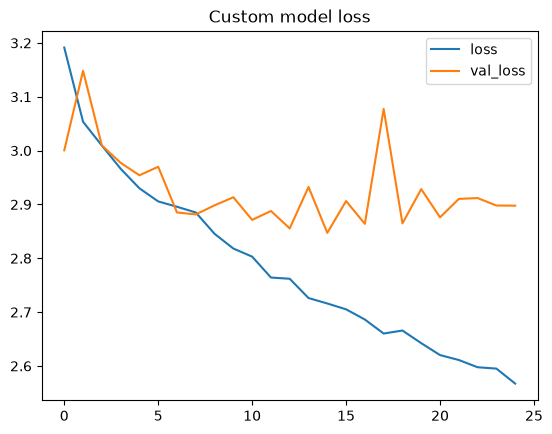

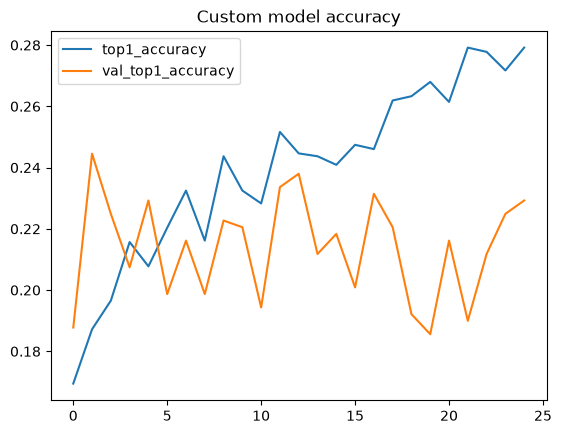

In [14]:
print("Validation:", custom_model.evaluate(custom_validation, return_dict=True))
print("Test:", custom_model.evaluate(custom_test, return_dict=True))
custom_probabilities = np.concatenate([
    np.asarray(custom_model(custom_test[i][0], training=False))
    for i in range(len(custom_test))
])
custom_reference = np.argmax(Y[custom_test.positions], axis=1)
print(classification_report(
    custom_reference, custom_probabilities.argmax(axis=1),
    labels=np.arange(len(custom_classes)), target_names=custom_classes,
    zero_division=0,
))
custom_history_frame = pd.DataFrame(custom_history.history)
custom_history_frame[["loss", "val_loss"]].plot(title="Custom model loss")
custom_history_frame[["top1_accuracy", "val_top1_accuracy"]].plot(title="Custom model accuracy")


In [15]:
# Save the restored best model and its inference inputs beside this notebook.
custom_model_path = notebook_dir / "SCIN_custom_model.keras"
custom_model.save(custom_model_path)
prepared.encoder.save(notebook_dir / "SCIN_custom_metadata_encoder.json")
(notebook_dir / "SCIN_custom_classes.json").write_text(
    json.dumps({"target_classes": custom_classes, "image_size": custom_image_size,
                "normalization": "RGB float32 /255, letterbox"}, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
print("Saved:", custom_model_path)


Saved: /Users/omarjibreen/College/Fall 2026/ProGSU/Hacklanta/PaliDerm/notebooks/SCIN_custom_model.keras


In [16]:
from scin_ml.data import MetadataEncoder  # Reuse the existing encoder loader.

custom_saved_model = keras.models.load_model(custom_model_path, compile=False)
custom_saved_encoder = MetadataEncoder.load(notebook_dir / "SCIN_custom_metadata_encoder.json")
custom_saved_config = json.loads((notebook_dir / "SCIN_custom_classes.json").read_text(encoding="utf-8"))
assert custom_saved_config["image_size"] == custom_image_size
assert custom_saved_model.output_shape[-1] == len(custom_saved_config["target_classes"])
assert custom_saved_model.get_layer("metadata").output.shape[-1] == custom_saved_encoder.output_dim


def predict_custom_dermatology(image, patient_metadata, top_k=3):
    """Return ranked uncalibrated scores from an image and complete SCIN metadata."""
    if not isinstance(top_k, int) or not 1 <= top_k <= len(custom_saved_config["target_classes"]):
        raise ValueError("top_k must be between 1 and the number of classes.")
    inputs = {"image": custom_image(image)[None],
              "metadata": custom_saved_encoder.transform(patient_metadata)}
    probabilities = np.asarray(custom_saved_model(inputs, training=False))[0]
    ranked = [{"diagnosis_name": custom_saved_config["target_classes"][int(i)],
               "probability": float(probabilities[i])}
              for i in np.argsort(-probabilities)]
    return {"probabilities": ranked, "top_predictions": ranked[:top_k]}


# Example: predict_custom_dermatology(image_bytes, complete_scin_metadata)
# The Flask AI adapter remains unchanged; this does not enable application inference.
